In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn mlflow fastapi uvicorn joblib reportlab -q

In [2]:
import pandas as pd
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

np.random.seed(42)

os.makedirs("omr_project", exist_ok=True)

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
n = 300

df = pd.DataFrame({
    "scan_resolution_dpi": np.random.randint(100, 601, n),
    "sheet_rotation_angle": np.random.uniform(-10, 10, n),
    "print_contrast_score": np.random.uniform(20, 100, n),
    "alignment_marker_visibility": np.random.uniform(0, 100, n),
    "multiple_marked_questions": np.random.randint(0, 21, n),
    "blank_answer_percentage": np.random.uniform(0, 100, n),
    "sheet_damage_score": np.random.uniform(0, 100, n),
    "scanner_type": np.random.choice(
        ["Flatbed", "ADF", "HighSpeed"], n
    )
})

risk = (
    (df["sheet_rotation_angle"].abs() > 3).astype(int) * 2 +
    (df["print_contrast_score"] < 45).astype(int) * 2 +
    (df["alignment_marker_visibility"] < 60).astype(int) * 2 +
    (df["multiple_marked_questions"] > 3).astype(int) * 2 +
    (df["sheet_damage_score"] > 50).astype(int) * 2 +
    (df["scan_resolution_dpi"] < 200).astype(int) +
    (df["blank_answer_percentage"] > 40).astype(int)
)

risk = risk + np.random.normal(0, 0.8, n)

df["scan_rejected"] = np.where(risk >= 5, "Yes", "No")

df.to_csv("omr_project/omr_version1.csv", index=False)

print(df.head())
print("Version 1 created:", df.shape)
print(df["scan_rejected"].value_counts())

   scan_resolution_dpi  sheet_rotation_angle  print_contrast_score  \
0                  202              5.232392             57.492851   
1                  535             -5.247249             24.504262   
2                  448              4.564327             29.505433   
3                  370             -2.644337             29.402100   
4                  206              2.646117             71.936824   

   alignment_marker_visibility  multiple_marked_questions  \
0                    53.346109                         20   
1                    89.389258                         11   
2                    78.859721                         15   
3                    15.167488                         11   
4                    31.172207                         14   

   blank_answer_percentage  sheet_damage_score scanner_type scan_rejected  
0                13.271575           99.125599          ADF           Yes  
1                56.754085           12.839429          ADF 

In [4]:
df2 = df.copy()

df2["sheet_rotation_angle"] = np.clip(
    df2["sheet_rotation_angle"] +
    np.random.choice([-5, 5], n),
    -15, 15
)

df2["print_contrast_score"] = np.clip(
    df2["print_contrast_score"] -
    np.random.uniform(10, 25, n),
    0, 100
)

risk2 = (
    (df2["sheet_rotation_angle"].abs() > 3).astype(int) * 2 +
    (df2["print_contrast_score"] < 45).astype(int) * 2 +
    (df2["alignment_marker_visibility"] < 60).astype(int) * 2 +
    (df2["multiple_marked_questions"] > 3).astype(int) * 2 +
    (df2["sheet_damage_score"] > 50).astype(int) * 2 +
    (df2["scan_resolution_dpi"] < 200).astype(int) +
    (df2["blank_answer_percentage"] > 40).astype(int)
)

risk2 = risk2 + np.random.normal(0, 0.8, n)

df2["scan_rejected"] = np.where(risk2 >= 5, "Yes", "No")

df2.to_csv("omr_project/omr_version2.csv", index=False)

print("Version 2 created:", df2.shape)
print(df2["scan_rejected"].value_counts())

Version 2 created: (300, 9)
scan_rejected
Yes    240
No      60
Name: count, dtype: int64


In [5]:
print("VERSION 1")
print(df.describe())

print("\nVERSION 2")
print(df2.describe())

print("\nVersion 1 rejection percentage:",
      (df["scan_rejected"] == "Yes").mean() * 100)

print("Version 2 rejection percentage:",
      (df2["scan_rejected"] == "Yes").mean() * 100)

VERSION 1
       scan_resolution_dpi  sheet_rotation_angle  print_contrast_score  \
count           300.000000            300.000000            300.000000   
mean            349.690000              0.110031             59.546311   
std             141.933403              5.917003             23.297369   
min             101.000000             -9.898768             20.972358   
25%             230.000000             -5.007702             39.153273   
50%             341.500000              0.764098             59.065571   
75%             472.250000              5.073387             79.800444   
max             600.000000              9.810103             99.977414   

       alignment_marker_visibility  multiple_marked_questions  \
count                   300.000000                 300.000000   
mean                     49.280012                   9.886667   
std                      29.329049                   5.928263   
min                       0.463202                   0.000000  

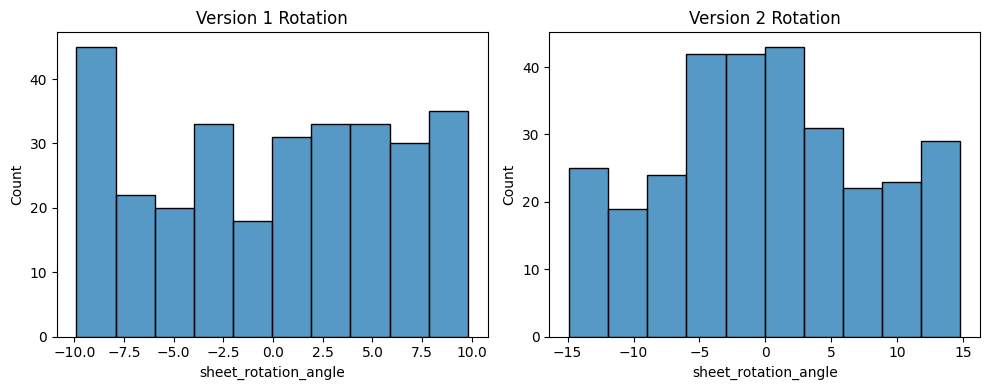

In [6]:

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.histplot(df["sheet_rotation_angle"])
plt.title("Version 1 Rotation")

plt.subplot(1, 2, 2)
sns.histplot(df2["sheet_rotation_angle"])
plt.title("Version 2 Rotation")

plt.tight_layout()
plt.show()


In [7]:
data = pd.read_csv("omr_project/omr_version2.csv")

data = data.drop_duplicates()

data["scan_resolution_dpi"] = data["scan_resolution_dpi"].fillna(
    data["scan_resolution_dpi"].median()
)

data["print_contrast_score"] = data["print_contrast_score"].fillna(
    data["print_contrast_score"].median()
)

print("Missing values:")
print(data.isnull().sum())

print("Preprocessing completed")

Missing values:
scan_resolution_dpi            0
sheet_rotation_angle           0
print_contrast_score           0
alignment_marker_visibility    0
multiple_marked_questions      0
blank_answer_percentage        0
sheet_damage_score             0
scanner_type                   0
scan_rejected                  0
dtype: int64
Preprocessing completed


In [8]:
data["scan_quality_index"] = (
    data["print_contrast_score"] * 0.25 +
    data["alignment_marker_visibility"] * 0.25 +
    (100 - data["sheet_rotation_angle"].abs() * 5) * 0.20 +
    (data["scan_resolution_dpi"] / 6) * 0.15 +
    (100 - data["sheet_damage_score"]) * 0.15
).clip(0, 100)

data["marking_error_ratio"] = (
    data["multiple_marked_questions"] +
    data["blank_answer_percentage"] / 10
) / 20

print(data[[
    "scan_quality_index",
    "marking_error_ratio"
]].head())

print("Feature engineering completed")

   scan_quality_index  marking_error_ratio
0           48.704825             1.066358
1           69.802547             0.833770
2           57.025853             1.094732
3           34.366615             0.950293
4           46.479263             0.800075
Feature engineering completed


In [9]:
feature_columns = [
    "scan_resolution_dpi",
    "sheet_rotation_angle",
    "print_contrast_score",
    "alignment_marker_visibility",
    "multiple_marked_questions",
    "blank_answer_percentage",
    "sheet_damage_score",
    "scanner_type",
    "scan_quality_index",
    "marking_error_ratio",
    "scan_rejected"
]

feature_store = data[feature_columns].copy()

feature_store.to_csv(
    "omr_project/omr_feature_store.csv",
    index=False
)

print("Feature Store created successfully")
print(feature_store.head())

Feature Store created successfully
   scan_resolution_dpi  sheet_rotation_angle  print_contrast_score  \
0                  202              0.232392             41.678119   
1                  535             -0.247249              5.013584   
2                  448              9.564327              8.947577   
3                  370             -7.644337             19.336651   
4                  206              7.646117             59.432528   

   alignment_marker_visibility  multiple_marked_questions  \
0                    53.346109                         20   
1                    89.389258                         11   
2                    78.859721                         15   
3                    15.167488                         11   
4                    31.172207                         14   

   blank_answer_percentage  sheet_damage_score scanner_type  \
0                13.271575           99.125599          ADF   
1                56.754085           12.839429     

In [10]:
reused_features = pd.read_csv(
    "omr_project/omr_feature_store.csv"
)

print("Reused Feature Store")
print(reused_features.head())

print("Total features:", len(reused_features.columns))

Reused Feature Store
   scan_resolution_dpi  sheet_rotation_angle  print_contrast_score  \
0                  202              0.232392             41.678119   
1                  535             -0.247249              5.013584   
2                  448              9.564327              8.947577   
3                  370             -7.644337             19.336651   
4                  206              7.646117             59.432528   

   alignment_marker_visibility  multiple_marked_questions  \
0                    53.346109                         20   
1                    89.389258                         11   
2                    78.859721                         15   
3                    15.167488                         11   
4                    31.172207                         14   

   blank_answer_percentage  sheet_damage_score scanner_type  \
0                13.271575           99.125599          ADF   
1                56.754085           12.839429          ADF   
2 

In [11]:
X = reused_features.drop("scan_rejected", axis=1)

y = reused_features["scan_rejected"].map({
    "No": 0,
    "Yes": 1
})

numeric_features = [
    "scan_resolution_dpi",
    "sheet_rotation_angle",
    "print_contrast_score",
    "alignment_marker_visibility",
    "multiple_marked_questions",
    "blank_answer_percentage",
    "sheet_damage_score",
    "scan_quality_index",
    "marking_error_ratio"
]

categorical_features = ["scanner_type"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 240
Testing records: 60


In [12]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, zero_division=0)

print("LOGISTIC REGRESSION")
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

LOGISTIC REGRESSION
Accuracy: 0.8166666666666667
Precision: 0.8490566037735849
Recall: 0.9375
F1 Score: 0.8910891089108911


In [13]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)

print("RANDOM FOREST")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

RANDOM FOREST
Accuracy: 0.8333333333333334
Precision: 0.8518518518518519
Recall: 0.9583333333333334
F1 Score: 0.9019607843137255


                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.816667   0.849057  0.937500  0.891089
1        Random Forest  0.833333   0.851852  0.958333  0.901961


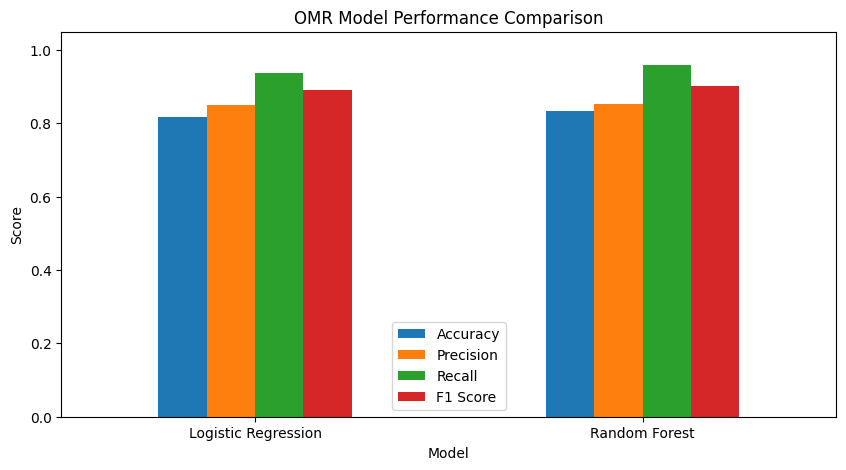

In [14]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [lr_accuracy, rf_accuracy],
    "Precision": [lr_precision, rf_precision],
    "Recall": [lr_recall, rf_recall],
    "F1 Score": [lr_f1, rf_f1]
})

print(results)

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("OMR Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()

In [15]:
if rf_recall > lr_recall:
    best_model = rf_model
    best_name = "Random Forest"
elif lr_recall > rf_recall:
    best_model = lr_model
    best_name = "Logistic Regression"
else:
    if rf_f1 >= lr_f1:
        best_model = rf_model
        best_name = "Random Forest"
    else:
        best_model = lr_model
        best_name = "Logistic Regression"

print("Selected Model:", best_name)

Selected Model: Random Forest


In [16]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///omr_mlflow.db")

mlflow.set_experiment("OMR_Rejection_Prediction")

print("MLflow configured successfully")

2026/11/18 08:51:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/18 08:51:16 INFO mlflow.store.db.utils: Updating database tables
2026/11/18 08:51:19 INFO mlflow.tracking.fluent: Experiment with name 'OMR_Rejection_Prediction' does not exist. Creating a new experiment.


MLflow configured successfully


In [18]:
joblib.dump(
    best_model,
    "omr_project/omr_model.pkl"
)

print("Model saved successfully")

Model saved successfully


In [19]:
%%writefile omr_project/app.py

from fastapi import FastAPI
from pydantic import BaseModel, Field
import joblib
import pandas as pd

app = FastAPI(title="OMR Rejection Prediction API")

model = joblib.load("omr_model.pkl")

class OMRInput(BaseModel):

    scan_resolution_dpi: float = Field(ge=50, le=1200)
    sheet_rotation_angle: float = Field(ge=-15, le=15)
    print_contrast_score: float = Field(ge=0, le=100)
    alignment_marker_visibility: float = Field(ge=0, le=100)
    multiple_marked_questions: int = Field(ge=0, le=100)
    blank_answer_percentage: float = Field(ge=0, le=100)
    sheet_damage_score: float = Field(ge=0, le=100)
    scanner_type: str

@app.get("/")
def home():
    return {"message": "OMR Prediction API is running"}

@app.post("/predict")
def predict(data: OMRInput):

    if data.scanner_type not in ["Flatbed", "ADF", "HighSpeed"]:
        return {"error": "Invalid scanner type"}

    scan_quality_index = (
        data.print_contrast_score * 0.25 +
        data.alignment_marker_visibility * 0.25 +
        (100 - abs(data.sheet_rotation_angle) * 5) * 0.20 +
        (data.scan_resolution_dpi / 6) * 0.15 +
        (100 - data.sheet_damage_score) * 0.15
    )

    marking_error_ratio = (
        data.multiple_marked_questions +
        data.blank_answer_percentage / 10
    ) / 20

    input_data = pd.DataFrame([{
        "scan_resolution_dpi": data.scan_resolution_dpi,
        "sheet_rotation_angle": data.sheet_rotation_angle,
        "print_contrast_score": data.print_contrast_score,
        "alignment_marker_visibility": data.alignment_marker_visibility,
        "multiple_marked_questions": data.multiple_marked_questions,
        "blank_answer_percentage": data.blank_answer_percentage,
        "sheet_damage_score": data.sheet_damage_score,
        "scanner_type": data.scanner_type,
        "scan_quality_index": scan_quality_index,
        "marking_error_ratio": marking_error_ratio
    }])

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        result = "Manual Verification Required"
    else:
        result = "Scan Accepted"

    return {
        "prediction": result,
        "scan_rejected": "Yes" if prediction == 1 else "No"
    }

Writing omr_project/app.py


In [21]:
%%writefile omr_project/app.py

from fastapi import FastAPI
from pydantic import BaseModel, Field
import joblib
import pandas as pd

app = FastAPI(title="OMR Rejection Prediction API")

model = joblib.load("omr_model.pkl")

class OMRInput(BaseModel):

    scan_resolution_dpi: float = Field(ge=50, le=1200)
    sheet_rotation_angle: float = Field(ge=-15, le=15)
    print_contrast_score: float = Field(ge=0, le=100)
    alignment_marker_visibility: float = Field(ge=0, le=100)
    multiple_marked_questions: int = Field(ge=0, le=100)
    blank_answer_percentage: float = Field(ge=0, le=100)
    sheet_damage_score: float = Field(ge=0, le=100)
    scanner_type: str

@app.get("/")
def home():
    return {"message": "OMR Prediction API is running"}

@app.post("/predict")
def predict(data: OMRInput):

    if data.scanner_type not in ["Flatbed", "ADF", "HighSpeed"]:
        return {"error": "Invalid scanner type"}

    scan_quality_index = (
        data.print_contrast_score * 0.25 +
        data.alignment_marker_visibility * 0.25 +
        (100 - abs(data.sheet_rotation_angle) * 5) * 0.20 +
        (data.scan_resolution_dpi / 6) * 0.15 +
        (100 - data.sheet_damage_score) * 0.15
    )

    marking_error_ratio = (
        data.multiple_marked_questions +
        data.blank_answer_percentage / 10
    ) / 20

    input_data = pd.DataFrame([{
        "scan_resolution_dpi": data.scan_resolution_dpi,
        "sheet_rotation_angle": data.sheet_rotation_angle,
        "print_contrast_score": data.print_contrast_score,
        "alignment_marker_visibility": data.alignment_marker_visibility,
        "multiple_marked_questions": data.multiple_marked_questions,
        "blank_answer_percentage": data.blank_answer_percentage,
        "sheet_damage_score": data.sheet_damage_score,
        "scanner_type": data.scanner_type,
        "scan_quality_index": scan_quality_index,
        "marking_error_ratio": marking_error_ratio
    }])

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        result = "Manual Verification Required"
    else:
        result = "Scan Accepted"

    return {
        "prediction": result,
        "scan_rejected": "Yes" if prediction == 1 else "No"
    }

Overwriting omr_project/app.py


In [23]:
import shutil

shutil.copy(
    "omr_project/omr_model.pkl",
    "omr_model.pkl"
)

'omr_model.pkl'

In [24]:
%cd /content/omr_project

!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > api.log 2>&1 &

/content/omr_project


In [25]:
import requests
import time

time.sleep(3)

url = "http://127.0.0.1:8000/predict"

sample = {
    "scan_resolution_dpi": 150,
    "sheet_rotation_angle": 8,
    "print_contrast_score": 30,
    "alignment_marker_visibility": 35,
    "multiple_marked_questions": 8,
    "blank_answer_percentage": 45,
    "sheet_damage_score": 70,
    "scanner_type": "ADF"
}

response = requests.post(url, json=sample)

print("Status Code:", response.status_code)
print("API Output:", response.json())

Status Code: 200
API Output: {'prediction': 'Manual Verification Required', 'scan_rejected': 'Yes'}


In [27]:
sample = {
    "scan_resolution_dpi": 400,
    "sheet_rotation_angle": 0.5,
    "print_contrast_score": 95,
    "alignment_marker_visibility": 98,
    "multiple_marked_questions": 0,
    "blank_answer_percentage": 5,
    "sheet_damage_score": 2,
    "scanner_type": "Flatbed"
}

response = requests.post(url, json=sample)

print(response.json())

{'prediction': 'Scan Accepted', 'scan_rejected': 'No'}


In [28]:
%%writefile test_omr.py

import joblib
import pandas as pd

def test_scanning_parameters():

    dpi = 300
    rotation = 5
    contrast = 80

    assert 50 <= dpi <= 1200
    assert -15 <= rotation <= 15
    assert 0 <= contrast <= 100

def test_model_prediction():

    model = joblib.load("omr_model.pkl")

    sample = pd.DataFrame([{
        "scan_resolution_dpi": 400,
        "sheet_rotation_angle": 1,
        "print_contrast_score": 90,
        "alignment_marker_visibility": 95,
        "multiple_marked_questions": 0,
        "blank_answer_percentage": 5,
        "sheet_damage_score": 5,
        "scanner_type": "Flatbed",
        "scan_quality_index": 90,
        "marking_error_ratio": 0.025
    }])

    prediction = model.predict(sample)

    assert prediction[0] in [0, 1]

Writing test_omr.py


In [29]:
%%writefile requirements.txt

pandas
numpy
scikit-learn
joblib
fastapi
uvicorn
pytest
mlflow

Writing requirements.txt


In [30]:
import os

os.makedirs(".github/workflows", exist_ok=True)

In [31]:
%%writefile .github/workflows/omr-ci.yml

name: OMR MLOps CI Pipeline

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout code
        uses: actions/checkout@v4

      - name: Setup Python
        uses: actions/setup-python@v5
        with:
          python-version: '3.11'

      - name: Install dependencies
        run: |
          pip install -r requirements.txt

      - name: Run automated tests
        run: |
          pytest -v

Writing .github/workflows/omr-ci.yml


In [33]:
!pip install pytest -q

In [34]:
%%writefile test_omr.py

import joblib
import pandas as pd

def test_scanning_parameters():
    dpi = 300
    rotation = 5
    contrast = 80

    assert 50 <= dpi <= 1200
    assert -15 <= rotation <= 15
    assert 0 <= contrast <= 100

def test_model_prediction():

    model = joblib.load("omr_model.pkl")

    data = pd.DataFrame([{
        "scan_resolution_dpi": 400,
        "sheet_rotation_angle": 1,
        "print_contrast_score": 90,
        "alignment_marker_visibility": 95,
        "multiple_marked_questions": 0,
        "blank_answer_percentage": 5,
        "sheet_damage_score": 5,
        "scanner_type": "Flatbed",
        "scan_quality_index": 90,
        "marking_error_ratio": 0.025
    }])

    prediction = model.predict(data)

    assert prediction[0] in [0, 1]

Overwriting test_omr.py


In [35]:
!pytest -v test_omr.py

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/omr_project
plugins: platformdirs-4.14.3, langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0
collected 2 items                                                              

test_omr.py::test_scanning_parameters PASSED                             [ 50%]
test_omr.py::test_model_prediction PASSED                                [100%]

============================== 2 passed in 2.67s ===============================


In [37]:
!pip install fastapi uvicorn requests -q

In [38]:
import os
import subprocess
import sys
import time

os.chdir("/content/omr_project")

server = subprocess.Popen([
    sys.executable, "-m", "uvicorn",
    "app:app",
    "--host", "127.0.0.1",
    "--port", "8000"
])

time.sleep(5)

print("FastAPI server started successfully")

FastAPI server started successfully


In [39]:
import requests

url = "http://127.0.0.1:8000/predict"

sample = {
    "scan_resolution_dpi": 150,
    "sheet_rotation_angle": 8,
    "print_contrast_score": 30,
    "alignment_marker_visibility": 35,
    "multiple_marked_questions": 8,
    "blank_answer_percentage": 45,
    "sheet_damage_score": 70,
    "scanner_type": "ADF"
}

response = requests.post(url, json=sample)

print("Status Code:", response.status_code)
print("Prediction Response:")
print(response.json())

Status Code: 200
Prediction Response:
{'prediction': 'Manual Verification Required', 'scan_rejected': 'Yes'}


In [40]:
sample = {
    "scan_resolution_dpi": 400,
    "sheet_rotation_angle": 0,
    "print_contrast_score": 95,
    "alignment_marker_visibility": 98,
    "multiple_marked_questions": 0,
    "blank_answer_percentage": 5,
    "sheet_damage_score": 2,
    "scanner_type": "Flatbed"
}

response = requests.post(url, json=sample)

print("Status Code:", response.status_code)
print("Prediction:", response.json())

Status Code: 200
Prediction: {'prediction': 'Scan Accepted', 'scan_rejected': 'No'}


In [41]:
import os

os.makedirs(".github/workflows", exist_ok=True)

In [42]:
%%writefile .github/workflows/omr-ci.yml

name: OMR MLOps CI Pipeline

on:
  push:
    branches: [main]

  pull_request:
    branches: [main]

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout Repository
        uses: actions/checkout@v4

      - name: Setup Python
        uses: actions/setup-python@v5
        with:
          python-version: '3.11'

      - name: Install Requirements
        run: pip install -r requirements.txt

      - name: Run Pytest
        run: pytest -v test_omr.py

Overwriting .github/workflows/omr-ci.yml


In [43]:
%%writefile requirements.txt

pandas
numpy
scikit-learn
joblib
fastapi
uvicorn
pytest

Overwriting requirements.txt


In [44]:
import os
import shutil

os.makedirs("OMR_GitHub", exist_ok=True)

for file in [
    "app.py",
    "omr_model.pkl",
    "test_omr.py",
    "requirements.txt"
]:
    shutil.copy(file, "OMR_GitHub")

shutil.copytree(
    ".github",
    "OMR_GitHub/.github",
    dirs_exist_ok=True
)

print("GitHub files prepared successfully")

GitHub files prepared successfully
